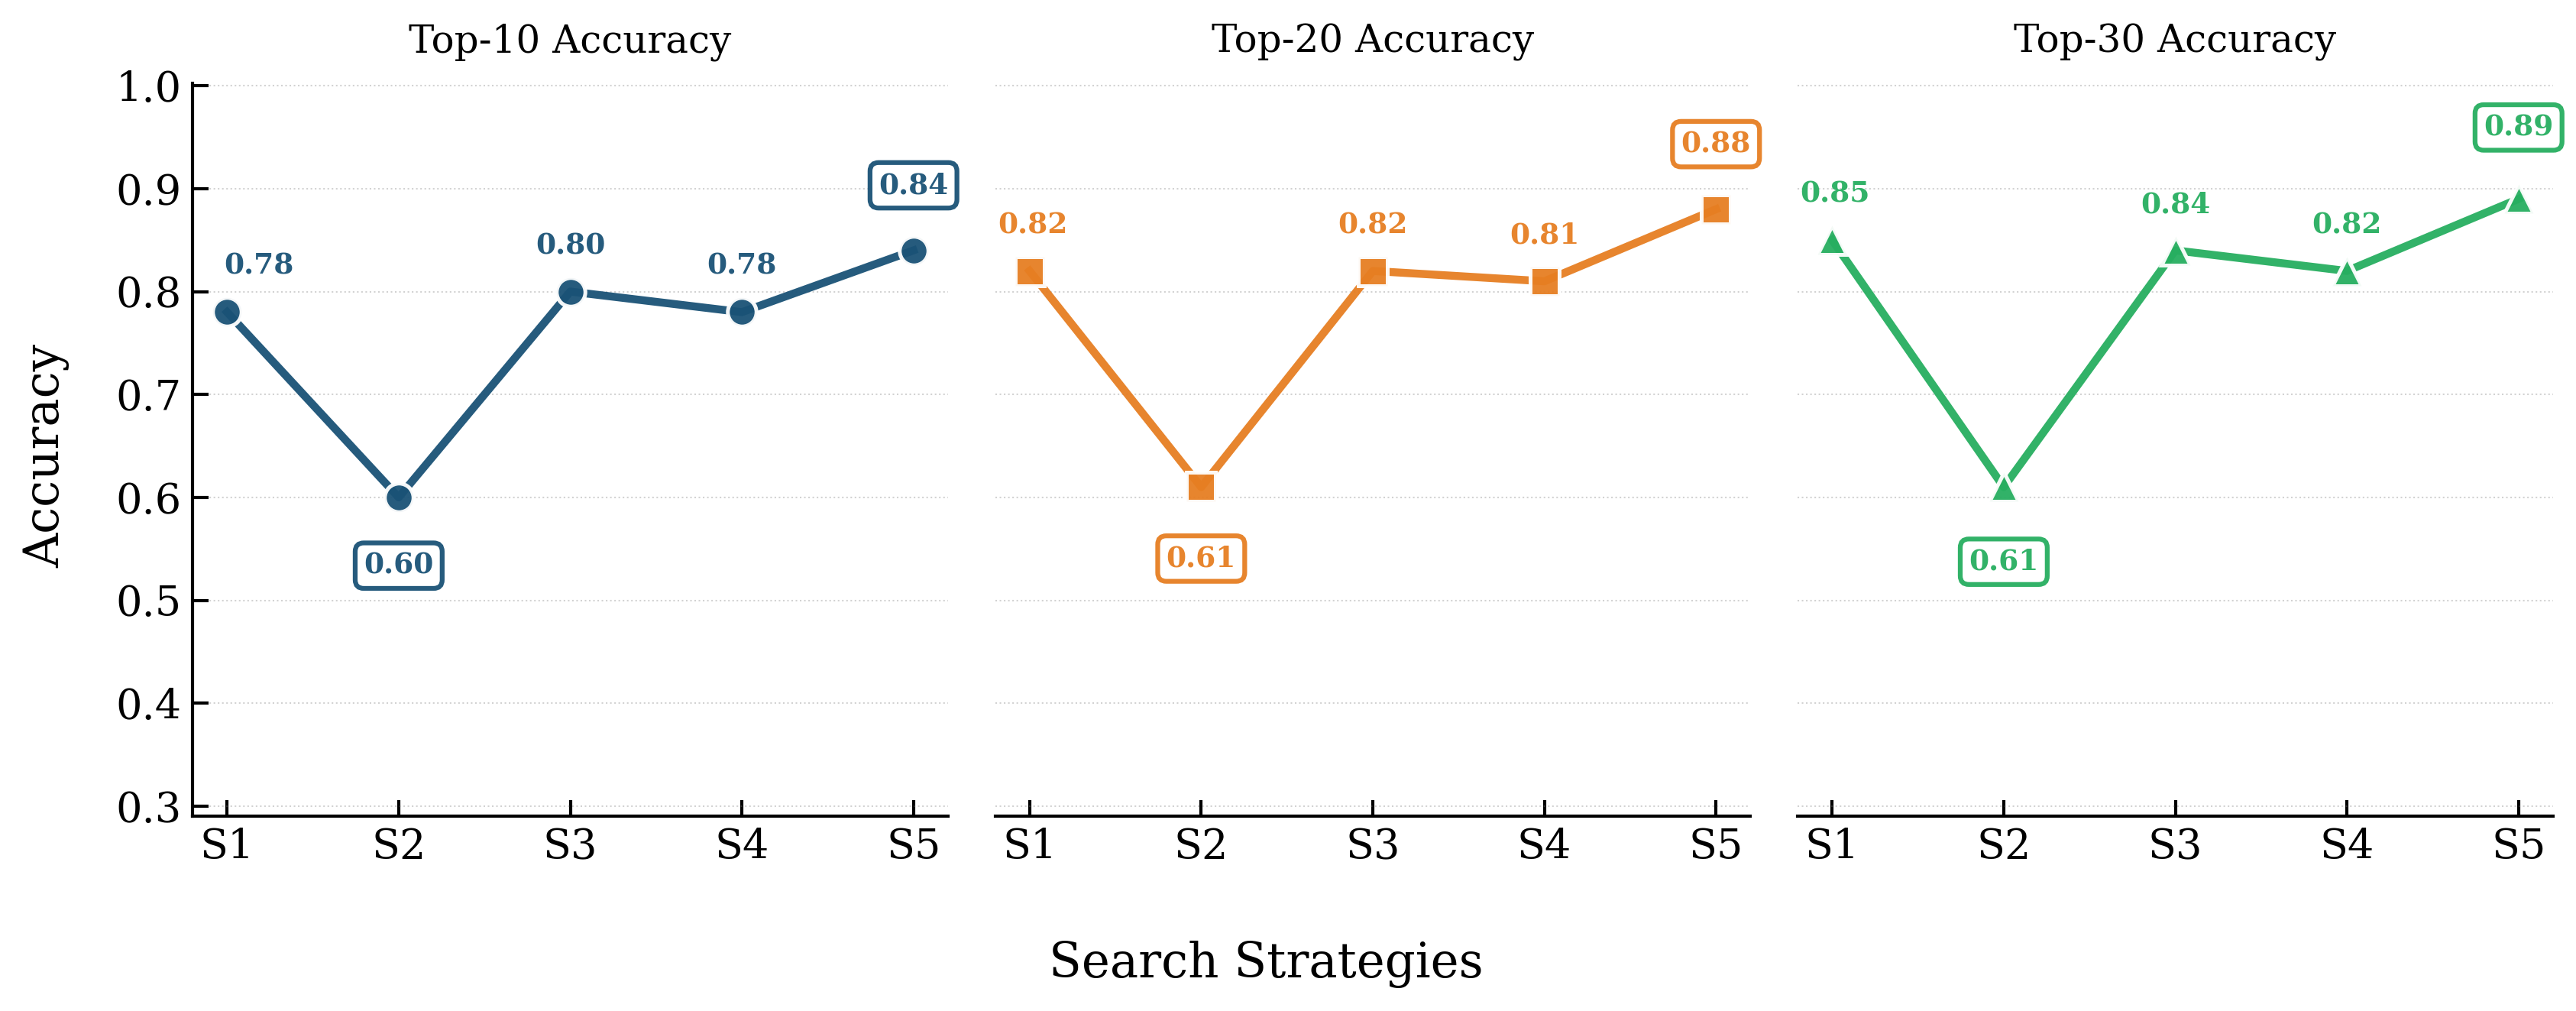

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# 数据
# -----------------------------
classes = ['S1', 'S2', 'S3', 'S4', 'S5']

# Top-10 acc for uspto-50k
top10_acc = [0.78, 0.60, 0.80, 0.78, 0.84]
# Top-20 acc
top20_acc = [0.82, 0.61, 0.82, 0.81, 0.88]
# Top-30 acc
top30_acc = [0.85, 0.61, 0.84, 0.82, 0.89]

x = np.arange(len(classes))

# -----------------------------
# 期刊级绘图设置
# -----------------------------
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'axes.labelsize': 15,
    'axes.titlesize': 15,
    'legend.fontsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 1.0,
    'xtick.major.width': 1.0,
    'ytick.major.width': 1.0,
})

# ---------- 颜色 ----------
colors = ['#1A5276', '#E67E22', '#27AE60']
titles = ['Top-10 Accuracy', 'Top-20 Accuracy', 'Top-30 Accuracy']
datasets = [top10_acc, top20_acc, top30_acc]
markers = ['o', 's', '^']

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), dpi=300, sharey=True)

# ========================
# 标注位置控制参数
# ========================
annot_configs = [
    # Top-10 标注配置 [S1, S2, S3, S4, S5]
    [(10, 10, 'bottom'), (0, -17, 'top'), (0, 10, 'bottom'), (0, 10, 'bottom'), (0, 16, 'bottom')],
    # Top-20 标注配置
    [(1, 10, 'bottom'), (0, -18, 'top'), (0, 10, 'bottom'), (0, 10, 'bottom'), (0, 16, 'bottom')],
    # Top-30 标注配置
    [(1, 10, 'bottom'), (0, -19, 'top'), (0, 10, 'bottom'), (0, 10, 'bottom'), (0, 18, 'bottom')],
]

for idx, (ax, data, title, color, marker, ann_conf) in enumerate(
    zip(axes, datasets, titles, colors, markers, annot_configs)):
    
    # 绘制折线
    ax.plot(
        x, data, color=color, marker=marker,
        linestyle='-', linewidth=2.5, markersize=9,
        markeredgecolor='white', markeredgewidth=1.2,
        markerfacecolor=color, alpha=0.95, zorder=3,
    )
    
    # ---------- 找出极值 ----------
    min_val = min(data)
    max_val = max(data)
    min_idx = data.index(min_val)
    max_idx = data.index(max_val)
    
    # ---------- 标注数值 ----------
    for i, val in enumerate(data):
        x_off, y_off, va = ann_conf[i]
        is_extreme = (i == min_idx or i == max_idx)
        
        # 构建bbox参数
        if is_extreme:
            bbox_props = dict(
                boxstyle='round,pad=0.3',
                facecolor='white',
                edgecolor=color,
                linewidth=1.5,
                alpha=0.95,
            )
        else:
            bbox_props = None
        
        ax.annotate(
            f'{val:.2f}', xy=(x[i], val), xytext=(x_off, y_off),
            textcoords='offset points', ha='center', va=va,
            fontsize=9, fontweight='bold', color=color,
            bbox=bbox_props,
            alpha=0.95, zorder=5,
        )
    
    # ---------- 标题 ----------
    ax.set_title(title, fontsize=12, pad=10)
    
    # ---------- 刻度 ----------
    ax.set_xticks(x)
    ax.set_xticklabels(classes, fontsize=13)
    ax.tick_params(direction='in', length=5, width=1.0, labelsize=13)
    
    # ---------- 第二个和第三个子图去掉左边纵坐标线 ----------
    if idx > 0:
        ax.spines['left'].set_visible(False)
        ax.tick_params(left=False)
    
    # ---------- 网格 ----------
    ax.yaxis.grid(True, linestyle=':', linewidth=0.5, alpha=0.35, color='gray')
    ax.set_axisbelow(True)
    
    # ---------- 边框 ----------
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.0)
    
    # Y轴范围
    ax.set_ylim(0.29, 1.002)

# ---------- 共享纵坐标标签 ----------
fig.text(0.04, 0.506, 'Accuracy', va='center', rotation='vertical', fontsize=15)

# ---------- 横坐标总标签 ----------
fig.text(0.492, 0, 'Search Strategies', ha='center', fontsize=15)

# ---------- 第一条纵坐标线保留 ----------
axes[0].spines['left'].set_visible(True)
axes[0].tick_params(left=True)

plt.tight_layout(rect=[0.060, 0.070, 0.976, 0.962])

# plt.savefig('figure2_final.png', dpi=300, bbox_inches='tight')
# plt.savefig('figure2_final.pdf', bbox_inches='tight')
plt.show()

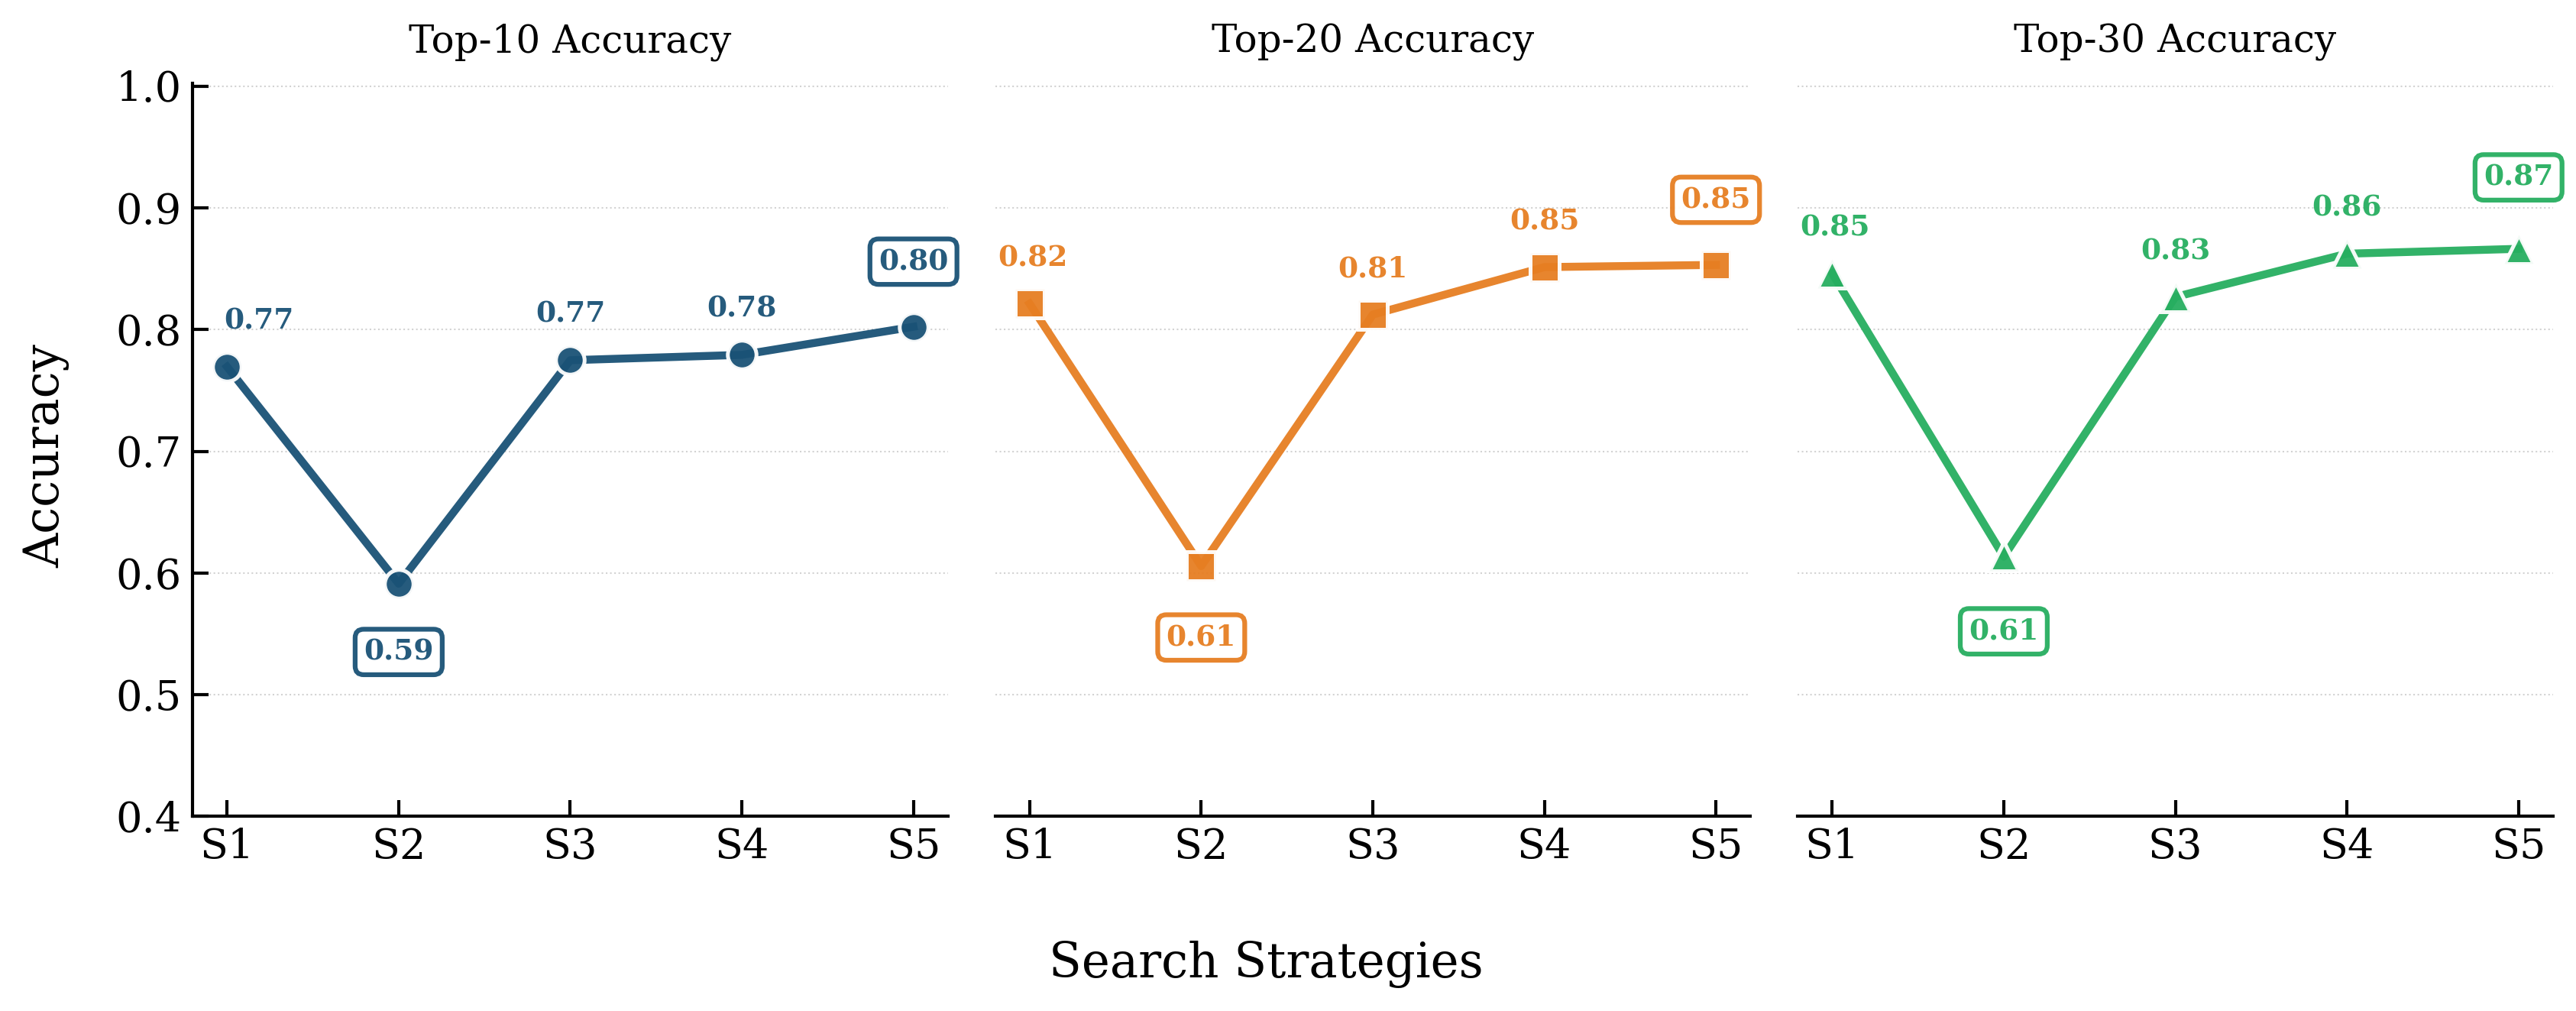

In [61]:
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# 数据
# -----------------------------
classes = ['S1', 'S2', 'S3', 'S4', 'S5']

# Knowledge distillation for uspto-50k


top10_acc = [0.7694, 0.5912, 0.7748, 0.7792, 0.8023]
top20_acc = [0.8212, 0.6057, 0.8123, 0.8513, 0.8531]
top30_acc = [0.8461, 0.6134, 0.8268, 0.8623, 0.8663]

x = np.arange(len(classes))

# -----------------------------
# 期刊级绘图设置
# -----------------------------
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'axes.labelsize': 15,
    'axes.titlesize': 15,
    'legend.fontsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 1.0,
    'xtick.major.width': 1.0,
    'ytick.major.width': 1.0,
})

# ---------- 颜色 ----------
colors = ['#1A5276', '#E67E22', '#27AE60']
titles = ['Top-10 Accuracy', 'Top-20 Accuracy', 'Top-30 Accuracy']
datasets = [top10_acc, top20_acc, top30_acc]
markers = ['o', 's', '^']

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), dpi=300, sharey=True)

# ========================
# 标注位置控制参数
# ========================
annot_configs = [
    # Top-10 标注配置 [S1, S2, S3, S4, S5]
    [(10, 10, 'bottom'), (0, -17, 'top'), (0, 10, 'bottom'), (0, 10, 'bottom'), (0, 16, 'bottom')],
    # Top-20 标注配置
    [(1, 10, 'bottom'), (0, -18, 'top'), (0, 10, 'bottom'), (0, 10, 'bottom'), (0, 16, 'bottom')],
    # Top-30 标注配置
    [(1, 10, 'bottom'), (0, -19, 'top'), (0, 10, 'bottom'), (0, 10, 'bottom'), (0, 18, 'bottom')],
]

for idx, (ax, data, title, color, marker, ann_conf) in enumerate(
    zip(axes, datasets, titles, colors, markers, annot_configs)):
    
    # 绘制折线
    ax.plot(
        x, data, color=color, marker=marker,
        linestyle='-', linewidth=2.5, markersize=9,
        markeredgecolor='white', markeredgewidth=1.2,
        markerfacecolor=color, alpha=0.95, zorder=3,
    )
    
    # ---------- 找出极值 ----------
    min_val = min(data)
    max_val = max(data)
    min_idx = data.index(min_val)
    max_idx = data.index(max_val)
    
    # ---------- 标注数值 ----------
    for i, val in enumerate(data):
        x_off, y_off, va = ann_conf[i]
        is_extreme = (i == min_idx or i == max_idx)
        
        # 构建bbox参数
        if is_extreme:
            bbox_props = dict(
                boxstyle='round,pad=0.3',
                facecolor='white',
                edgecolor=color,
                linewidth=1.5,
                alpha=0.95,
            )
        else:
            bbox_props = None
        
        ax.annotate(
            f'{val:.2f}', xy=(x[i], val), xytext=(x_off, y_off),
            textcoords='offset points', ha='center', va=va,
            fontsize=9, fontweight='bold', color=color,
            bbox=bbox_props,
            alpha=0.95, zorder=5,
        )
    
    # ---------- 标题 ----------
    ax.set_title(title, fontsize=12, pad=10)
    
    # ---------- 刻度 ----------
    ax.set_xticks(x)
    ax.set_xticklabels(classes, fontsize=13)
    ax.tick_params(direction='in', length=5, width=1.0, labelsize=13)
    
    # ---------- 第二个和第三个子图去掉左边纵坐标线 ----------
    if idx > 0:
        ax.spines['left'].set_visible(False)
        ax.tick_params(left=False)
    
    # ---------- 网格 ----------
    ax.yaxis.grid(True, linestyle=':', linewidth=0.5, alpha=0.35, color='gray')
    ax.set_axisbelow(True)
    
    # ---------- 边框 ----------
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.0)
    
    # Y轴范围
    ax.set_ylim(0.4, 1.002)

# ---------- 共享纵坐标标签 ----------
fig.text(0.04, 0.506, 'Accuracy', va='center', rotation='vertical', fontsize=15)

# ---------- 横坐标总标签 ----------
fig.text(0.492, 0, 'Search Strategies', ha='center', fontsize=15)

# ---------- 第一条纵坐标线保留 ----------
axes[0].spines['left'].set_visible(True)
axes[0].tick_params(left=True)

plt.tight_layout(rect=[0.060, 0.070, 0.976, 0.962])

# plt.savefig('figure2_final.png', dpi=300, bbox_inches='tight')
# plt.savefig('figure2_final.pdf', bbox_inches='tight')
plt.show()

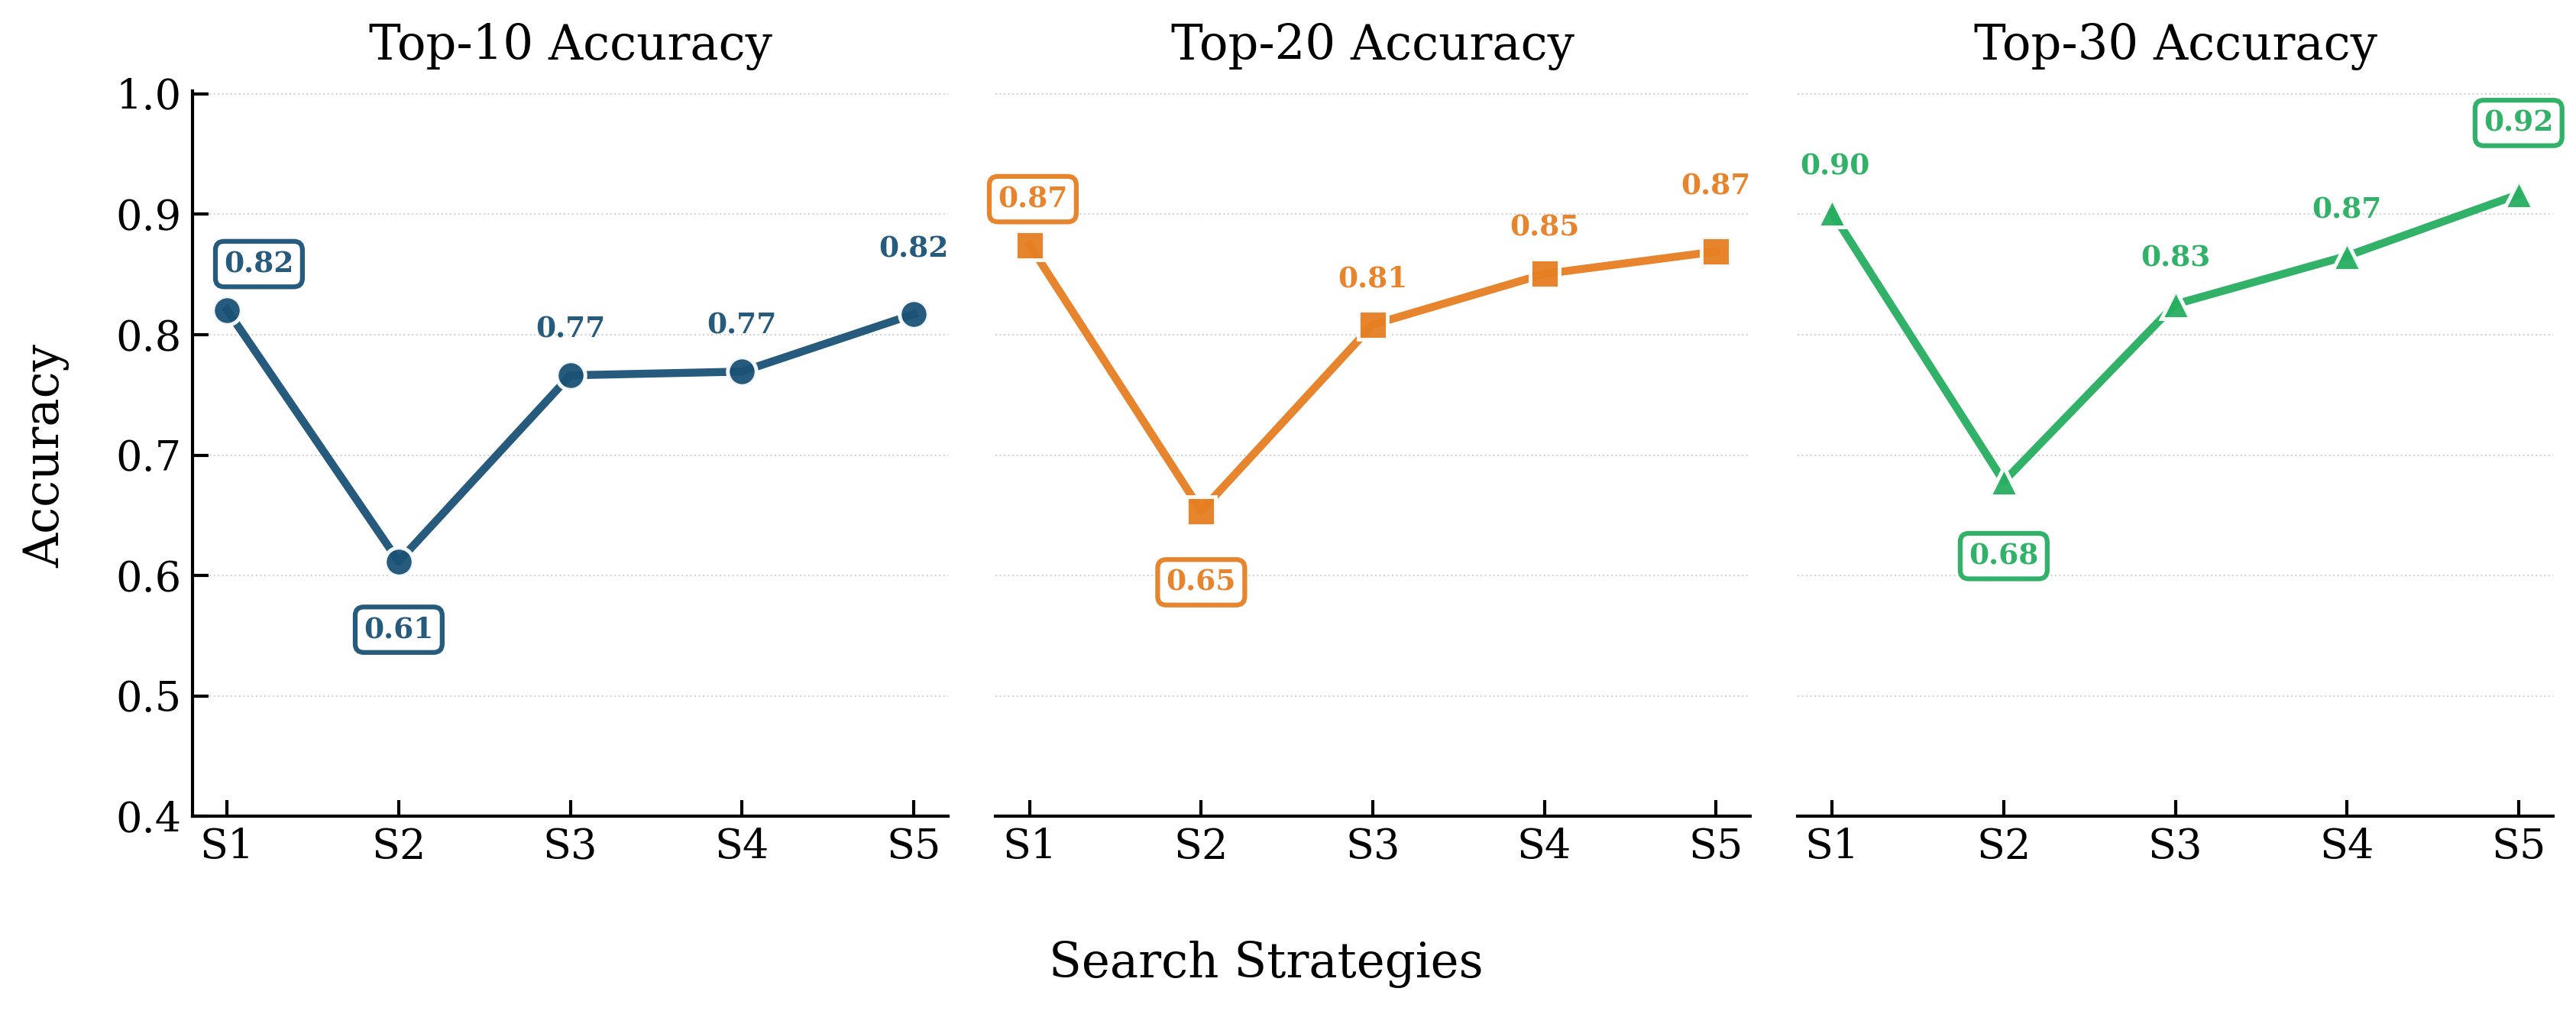

In [54]:
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# 数据
# -----------------------------
classes = ['S1', 'S2', 'S3', 'S4', 'S5']

# paroutes-1M
top10_acc = [0.8204, 0.6117, 0.7662, 0.7693, 0.8169]
top20_acc = [0.8743, 0.6537, 0.8083, 0.8504, 0.8690]
top30_acc = [0.9012, 0.6781, 0.8252, 0.8653, 0.9164]

x = np.arange(len(classes))

# -----------------------------
# 期刊级绘图设置
# -----------------------------
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'axes.labelsize': 15,
    'axes.titlesize': 15,
    'legend.fontsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 1.0,
    'xtick.major.width': 1.0,
    'ytick.major.width': 1.0,
})

# ---------- 颜色 ----------
colors = ['#1A5276', '#E67E22', '#27AE60']
titles = ['Top-10 Accuracy', 'Top-20 Accuracy', 'Top-30 Accuracy']
datasets = [top10_acc, top20_acc, top30_acc]
markers = ['o', 's', '^']

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), dpi=300, sharey=True)

# ========================
# 标注位置控制参数
# ========================
annot_configs = [
    # Top-10 标注配置 [S1, S2, S3, S4, S5]
    [(10, 10, 'bottom'), (0, -17, 'top'), (0, 10, 'bottom'), (0, 10, 'bottom'), (0, 16, 'bottom')],
    # Top-20 标注配置
    [(1, 10, 'bottom'), (0, -18, 'top'), (0, 10, 'bottom'), (0, 10, 'bottom'), (0, 16, 'bottom')],
    # Top-30 标注配置
    [(1, 10, 'bottom'), (0, -19, 'top'), (0, 10, 'bottom'), (0, 10, 'bottom'), (0, 18, 'bottom')],
]

for idx, (ax, data, title, color, marker, ann_conf) in enumerate(
    zip(axes, datasets, titles, colors, markers, annot_configs)):
    
    # 绘制折线
    ax.plot(
        x, data, color=color, marker=marker,
        linestyle='-', linewidth=2.5, markersize=9,
        markeredgecolor='white', markeredgewidth=1.2,
        markerfacecolor=color, alpha=0.95, zorder=3,
    )
    
    # ---------- 找出极值 ----------
    min_val = min(data)
    max_val = max(data)
    min_idx = data.index(min_val)
    max_idx = data.index(max_val)
    
    # ---------- 标注数值 ----------
    for i, val in enumerate(data):
        x_off, y_off, va = ann_conf[i]
        is_extreme = (i == min_idx or i == max_idx)
        
        # 构建bbox参数
        if is_extreme:
            bbox_props = dict(
                boxstyle='round,pad=0.3',
                facecolor='white',
                edgecolor=color,
                linewidth=1.5,
                alpha=0.95,
            )
        else:
            bbox_props = None
        
        ax.annotate(
            f'{val:.2f}', xy=(x[i], val), xytext=(x_off, y_off),
            textcoords='offset points', ha='center', va=va,
            fontsize=9, fontweight='bold', color=color,
            bbox=bbox_props,
            alpha=0.95, zorder=5,
        )
    
    # ---------- 标题 ----------
    ax.set_title(title, fontsize=15, pad=10)
    
    # ---------- 刻度 ----------
    ax.set_xticks(x)
    ax.set_xticklabels(classes, fontsize=13)
    ax.tick_params(direction='in', length=5, width=1.0, labelsize=13)
    
    # ---------- 第二个和第三个子图去掉左边纵坐标线 ----------
    if idx > 0:
        ax.spines['left'].set_visible(False)
        ax.tick_params(left=False)
    
    # ---------- 网格 ----------
    ax.yaxis.grid(True, linestyle=':', linewidth=0.5, alpha=0.35, color='gray')
    ax.set_axisbelow(True)
    
    # ---------- 边框 ----------
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.0)
    
    # Y轴范围
    ax.set_ylim(0.4, 1.002)

# ---------- 共享纵坐标标签 ----------
fig.text(0.04, 0.506, 'Accuracy', va='center', rotation='vertical', fontsize=15)

# ---------- 横坐标总标签 ----------
fig.text(0.492, 0, 'Search Strategies', ha='center', fontsize=15)

# ---------- 第一条纵坐标线保留 ----------
axes[0].spines['left'].set_visible(True)
axes[0].tick_params(left=True)

plt.tight_layout(rect=[0.060, 0.070, 0.976, 0.962])

# plt.savefig('figure2_final.png', dpi=300, bbox_inches='tight')
# plt.savefig('figure2_final.pdf', bbox_inches='tight')
plt.show()

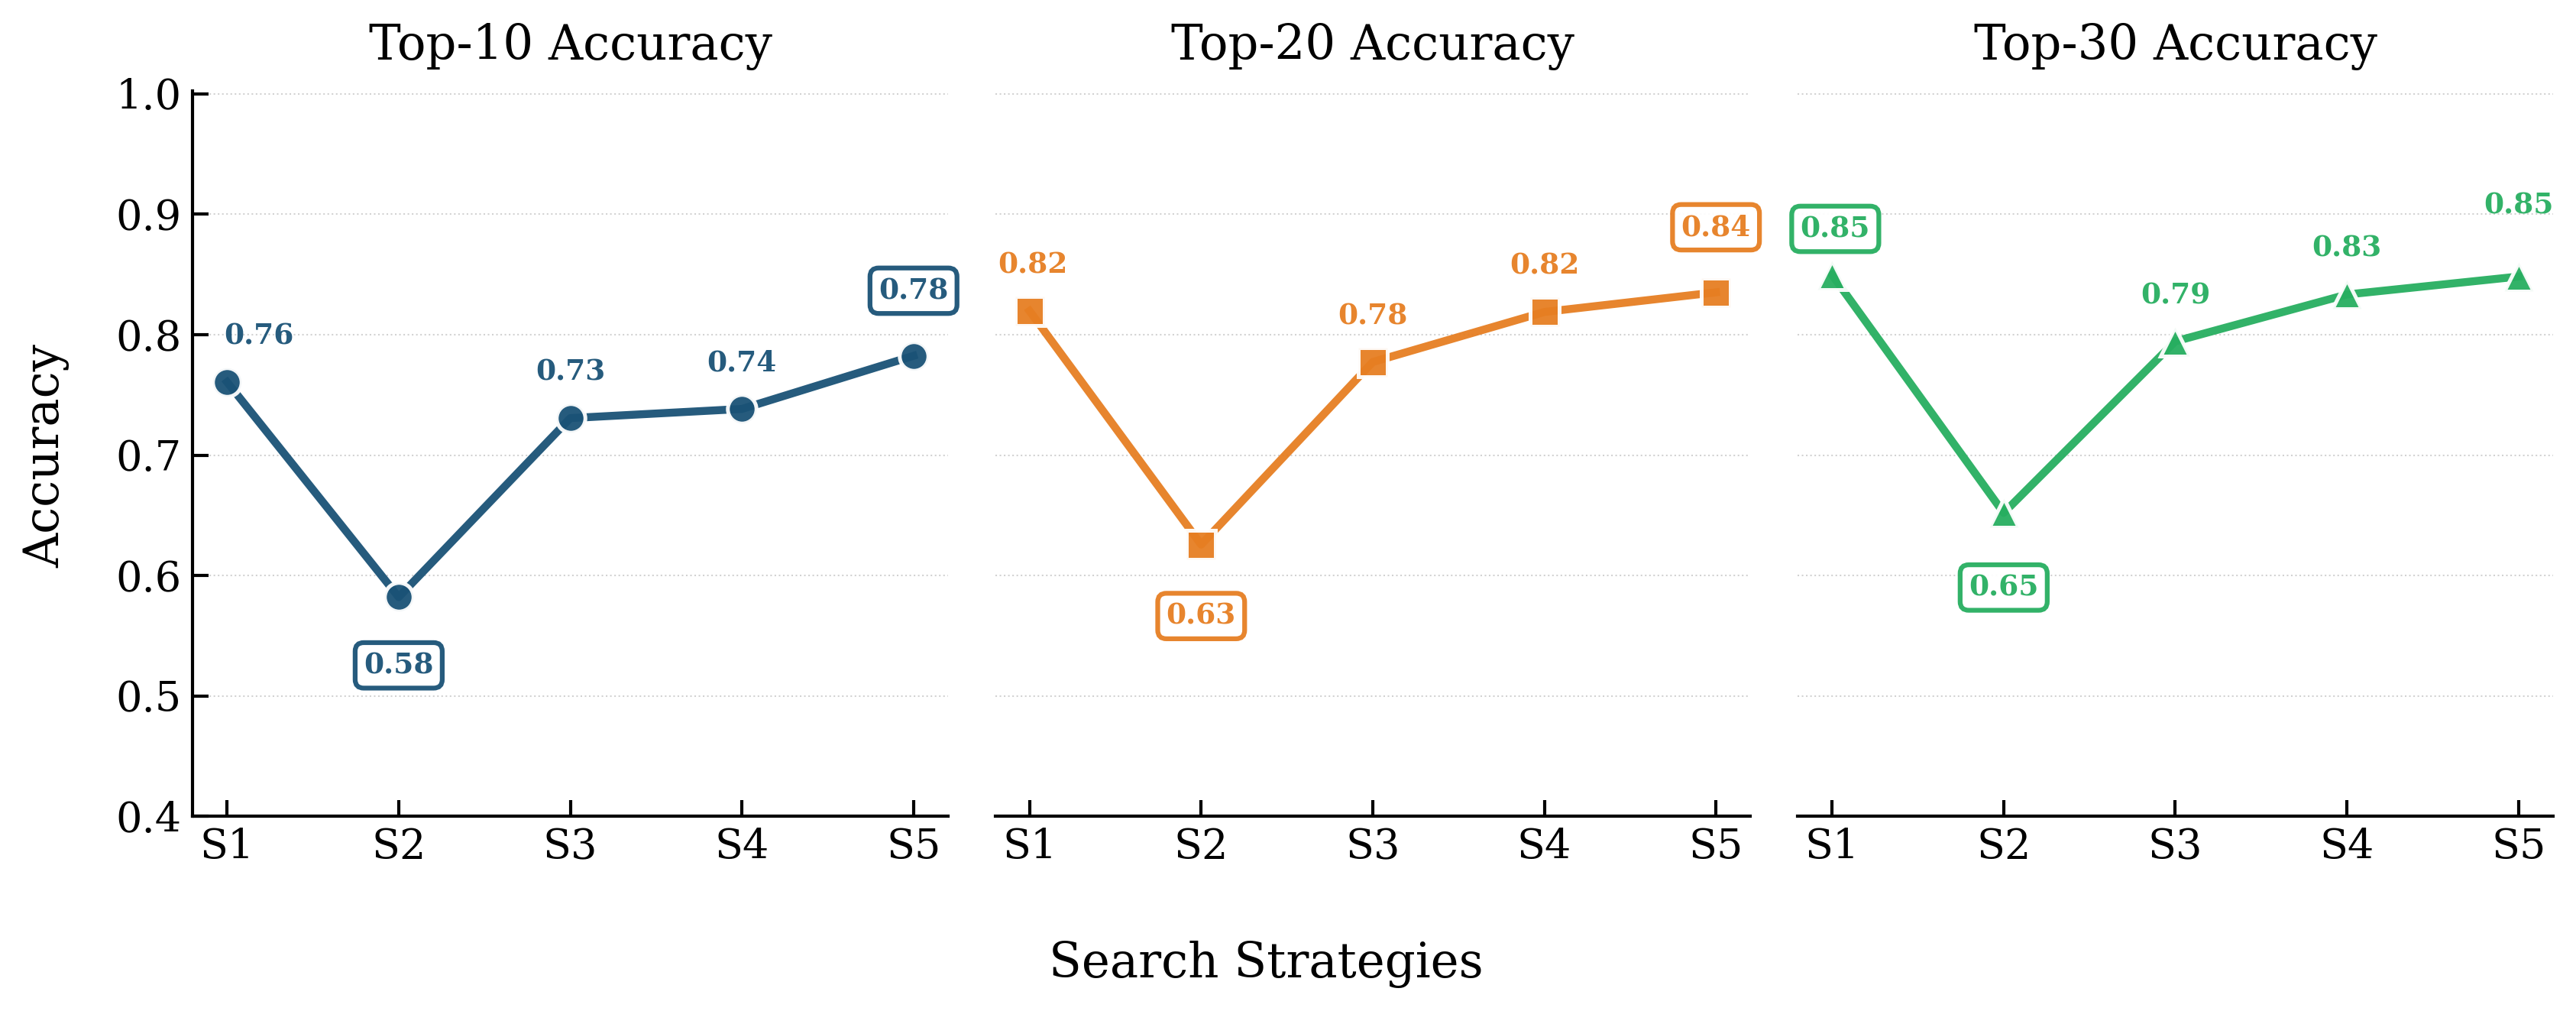

In [62]:
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# 数据
# -----------------------------
classes = ['S1', 'S2', 'S3', 'S4', 'S5']

# paroutes-1M for knowledge distillation
top10_acc = [0.8204, 0.6117, 0.7662, 0.7693, 0.8169]
top20_acc = [0.8743, 0.6537, 0.8083, 0.8504, 0.8690]
top30_acc = [0.9012, 0.6781, 0.8252, 0.8653, 0.9164]
top10_acc = [0.7606, 0.5821, 0.7307, 0.7383, 0.7824]
top20_acc = [0.8196, 0.6257, 0.7773, 0.8188, 0.8351]
top30_acc = [0.8496, 0.6520, 0.7944, 0.8333, 0.8482]
x = np.arange(len(classes))

# -----------------------------
# 期刊级绘图设置
# -----------------------------
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'axes.labelsize': 15,
    'axes.titlesize': 15,
    'legend.fontsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 1.0,
    'xtick.major.width': 1.0,
    'ytick.major.width': 1.0,
})

# ---------- 颜色 ----------
colors = ['#1A5276', '#E67E22', '#27AE60']
titles = ['Top-10 Accuracy', 'Top-20 Accuracy', 'Top-30 Accuracy']
datasets = [top10_acc, top20_acc, top30_acc]
markers = ['o', 's', '^']

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), dpi=300, sharey=True)

# ========================
# 标注位置控制参数
# ========================
annot_configs = [
    # Top-10 标注配置 [S1, S2, S3, S4, S5]
    [(10, 10, 'bottom'), (0, -17, 'top'), (0, 10, 'bottom'), (0, 10, 'bottom'), (0, 16, 'bottom')],
    # Top-20 标注配置
    [(1, 10, 'bottom'), (0, -18, 'top'), (0, 10, 'bottom'), (0, 10, 'bottom'), (0, 16, 'bottom')],
    # Top-30 标注配置
    [(1, 10, 'bottom'), (0, -19, 'top'), (0, 10, 'bottom'), (0, 10, 'bottom'), (0, 18, 'bottom')],
]

for idx, (ax, data, title, color, marker, ann_conf) in enumerate(
    zip(axes, datasets, titles, colors, markers, annot_configs)):
    
    # 绘制折线
    ax.plot(
        x, data, color=color, marker=marker,
        linestyle='-', linewidth=2.5, markersize=9,
        markeredgecolor='white', markeredgewidth=1.2,
        markerfacecolor=color, alpha=0.95, zorder=3,
    )
    
    # ---------- 找出极值 ----------
    min_val = min(data)
    max_val = max(data)
    min_idx = data.index(min_val)
    max_idx = data.index(max_val)
    
    # ---------- 标注数值 ----------
    for i, val in enumerate(data):
        x_off, y_off, va = ann_conf[i]
        is_extreme = (i == min_idx or i == max_idx)
        
        # 构建bbox参数
        if is_extreme:
            bbox_props = dict(
                boxstyle='round,pad=0.3',
                facecolor='white',
                edgecolor=color,
                linewidth=1.5,
                alpha=0.95,
            )
        else:
            bbox_props = None
        
        ax.annotate(
            f'{val:.2f}', xy=(x[i], val), xytext=(x_off, y_off),
            textcoords='offset points', ha='center', va=va,
            fontsize=9, fontweight='bold', color=color,
            bbox=bbox_props,
            alpha=0.95, zorder=5,
        )
    
    # ---------- 标题 ----------
    ax.set_title(title, fontsize=15, pad=10)
    
    # ---------- 刻度 ----------
    ax.set_xticks(x)
    ax.set_xticklabels(classes, fontsize=13)
    ax.tick_params(direction='in', length=5, width=1.0, labelsize=13)
    
    # ---------- 第二个和第三个子图去掉左边纵坐标线 ----------
    if idx > 0:
        ax.spines['left'].set_visible(False)
        ax.tick_params(left=False)
    
    # ---------- 网格 ----------
    ax.yaxis.grid(True, linestyle=':', linewidth=0.5, alpha=0.35, color='gray')
    ax.set_axisbelow(True)
    
    # ---------- 边框 ----------
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.0)
    
    # Y轴范围
    ax.set_ylim(0.4, 1.002)

# ---------- 共享纵坐标标签 ----------
fig.text(0.04, 0.506, 'Accuracy', va='center', rotation='vertical', fontsize=15)

# ---------- 横坐标总标签 ----------
fig.text(0.492, 0, 'Search Strategies', ha='center', fontsize=15)

# ---------- 第一条纵坐标线保留 ----------
axes[0].spines['left'].set_visible(True)
axes[0].tick_params(left=True)

plt.tight_layout(rect=[0.060, 0.070, 0.976, 0.962])

# plt.savefig('figure2_final.png', dpi=300, bbox_inches='tight')
# plt.savefig('figure2_final.pdf', bbox_inches='tight')
plt.show()

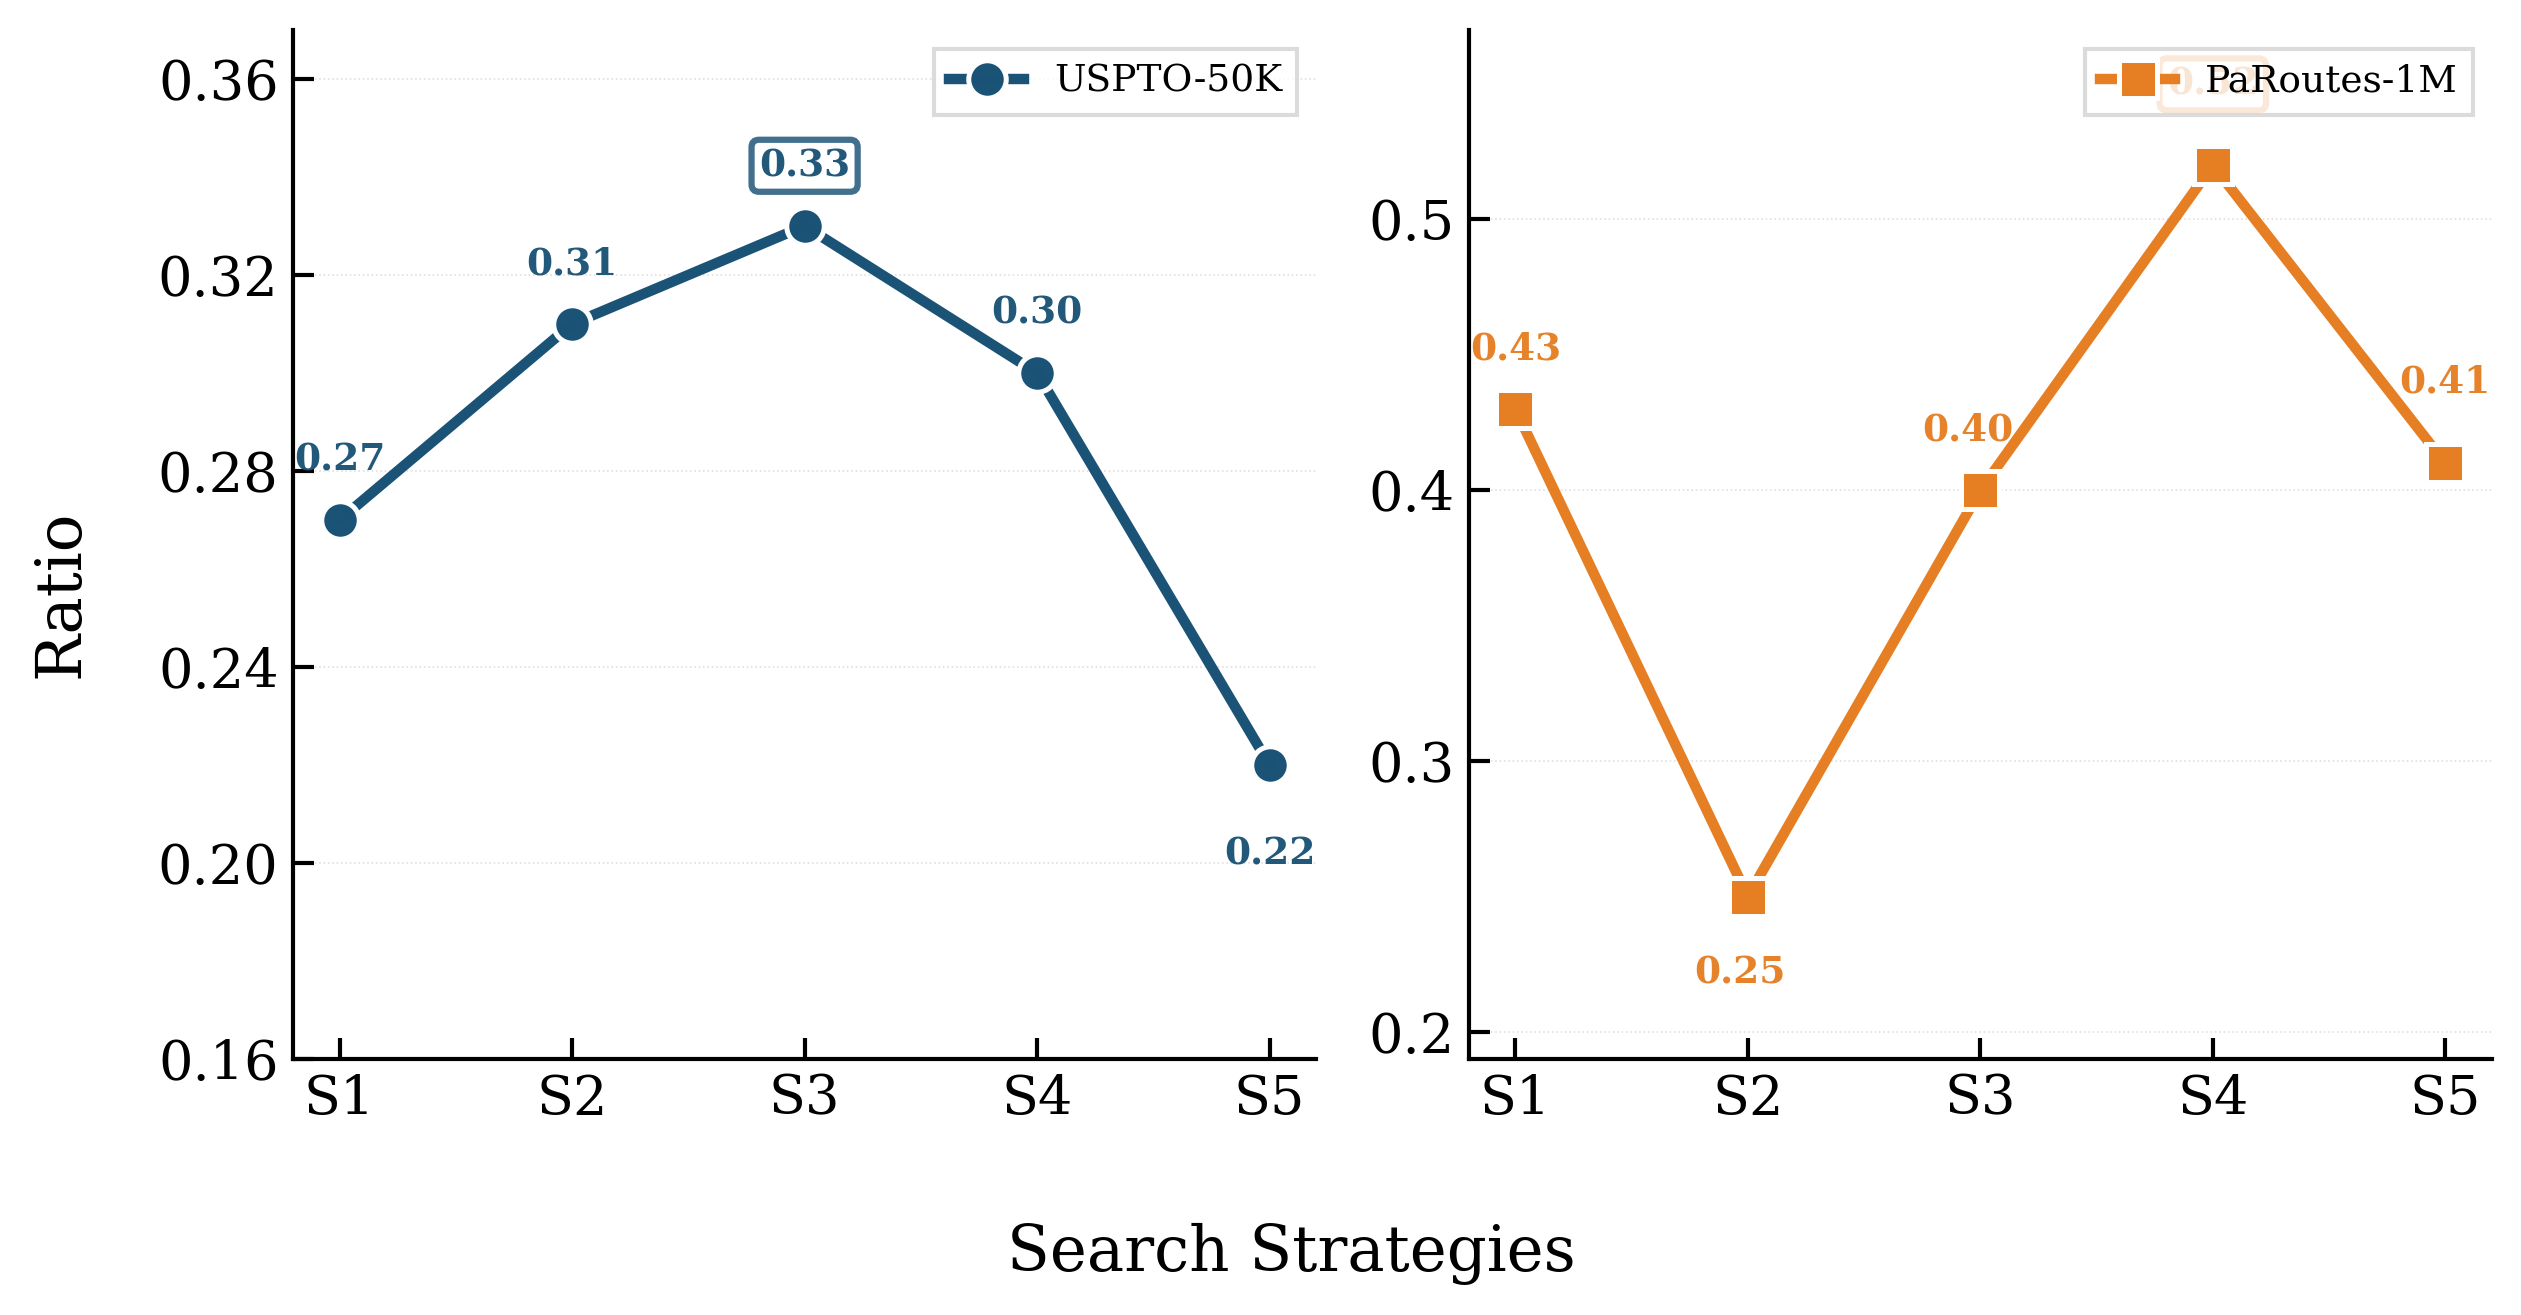

In [59]:
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# 数据
# -----------------------------
classes = ['S1', 'S2', 'S3', 'S4', 'S5']

# 两个数据集
uspto_50k = [0.27, 0.31, 0.33, 0.30, 0.22]
paroute_1m = [0.43, 0.25, 0.40, 0.52, 0.41]

x = np.arange(len(classes))

# -----------------------------
# 期刊级绘图设置
# -----------------------------
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'axes.labelsize': 15,
    'axes.titlesize': 10,
    'legend.fontsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 1.0,
    'xtick.major.width': 1.0,
    'ytick.major.width': 1.0,
})

# ---------- 颜色 ----------
colors = ['#1A5276', '#E67E22']
titles = ['USPTO-50K', 'PaRoutes-1M']
datasets = [uspto_50k, paroute_1m]
markers = ['o', 's']
legend_labels = ['USPTO-50K', 'PaRoutes-1M']

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), dpi=300)

# ========================
# 标注位置控制参数
# ========================
annot_configs = [
    # USPTO-50K 标注配置 [S1, S2, S3, S4, S5]
    [(0, 10, 'bottom'), (0, 10, 'bottom'), (0, 10, 'bottom'), (0, 10, 'bottom'), (0, -17, 'top')],
    # PaRoutes-1M 标注配置
    [(0, 10, 'bottom'), (-2, -14, 'top'), (-3, 10, 'bottom'), (0, 15, 'bottom'), (0, 15, 'bottom')],
]

# ========================
# 各自纵坐标范围和刻度
# ========================
ylims = [(0.160, 0.370), (0.190, 0.570)]
yticks_list = [
    [0.16, 0.20, 0.24, 0.28, 0.32, 0.36],
    [0.20, 0.30, 0.40, 0.50],
]

for idx, (ax, data, title, color, marker, ann_conf, ylim, yticks) in enumerate(
    zip(axes, datasets, titles, colors, markers, annot_configs, ylims, yticks_list)):
    
    # 绘制折线
    line, = ax.plot(
        x, data, color=color, marker=marker,
        linestyle='-', linewidth=2.5, markersize=9,
        markeredgecolor='white', markeredgewidth=1.2,
        markerfacecolor=color, alpha=0.995, zorder=3,
        label=legend_labels[idx],
    )
    
    # ---------- 找出极值 ----------
    max_val = max(data)
    max_idx = data.index(max_val)
    
    # ---------- 标注数值 ----------
    for i, val in enumerate(data):
        x_off, y_off, va = ann_conf[i]
        is_max = (i == max_idx)
        
        if is_max:
            bbox_props = dict(
                boxstyle='round,pad=0.20',
                facecolor='white',
                edgecolor=color,
                linewidth=1.5,
                alpha=0.83,
            )
        else:
            bbox_props = None
        
        ax.annotate(
            f'{val:.2f}', xy=(x[i], val), xytext=(x_off, y_off),
            textcoords='offset points', ha='center', va=va,
            fontsize=9, fontweight='bold', color=color,
            bbox=bbox_props,
            alpha=0.968, zorder=5,
        )
    
    # ---------- 标题 ----------
    # ax.set_title(title, fontsize=10, pad=10, fontweight='bold')
    
    # ---------- 刻度 ----------
    ax.set_xticks(x)
    ax.set_xticklabels(classes, fontsize=13)
    ax.set_yticks(yticks)
    ax.tick_params(direction='in', length=5, width=1.0, labelsize=13)
    
    # ---------- 第二个子图保留纵坐标 ----------
    if idx > 0:
        ax.spines['left'].set_visible(True)
        ax.tick_params(left=True)
    
    # ---------- 网格 ----------
    ax.yaxis.grid(True, linestyle=':', linewidth=0.395, alpha=0.255, color='gray')
    ax.set_axisbelow(True)
    
    # ---------- 边框 ----------
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.0)
    
    # Y轴范围
    ax.set_ylim(ylim)
    
    # ---------- 图例 ----------
    ax.legend(frameon=True, fancybox=False, edgecolor='lightgray',
              loc='upper right', fontsize=9)

# ---------- 共享纵坐标标签 ----------
fig.text(0.042, 0.490, 'Ratio', va='center', rotation='vertical', fontsize=15)

# ---------- 横坐标总标签 ----------
fig.text(0.509, -0.012, 'Search Strategies', ha='center', fontsize=15)

plt.tight_layout(rect=[0.071, 0.059, 0.973, 0.944])

# plt.savefig('figure2_with_legend.png', dpi=300, bbox_inches='tight')
# plt.savefig('figure2_with_legend.pdf', bbox_inches='tight')
plt.show()